# Exploring specificity prediction normalisation

In this notebook, we explore whether our developped model can normalise the effects that come from more confident structure prediction.

In [1]:
import h5py
import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
import torch
import umap
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from scipy import stats
from sklearn.metrics import roc_auc_score

from tcr_pmhc_predicted_structures.models import PAEAggregator

2026-03-09 16:44:06.671289: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500
SEED = 123

In [3]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500_af_training.csv', index_col='id')

In [4]:
confidence_scores_1500 = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
confidence_scores_1500['name'] = confidence_scores_1500['name'].astype(str)

confidence_scores_af_training = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_af_training.csv')

confidence_scores = pd.concat([confidence_scores_1500, confidence_scores_af_training]).reset_index(drop=True)

In [5]:
confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

In [6]:
confidence_scores['type'] = confidence_scores['label'].map(lambda label: 'Binder' if label else 'Non-Binder')

In [7]:
min_size = confidence_scores.value_counts(['source', 'label']).min()
confidence_scores_down_sample = confidence_scores.groupby(['source', 'label']).sample(min_size, random_state=123)

In [8]:
sequences_1500 = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences_1500.index = sequences_1500.index.astype(str)

In [9]:
sequences_1500['type'] = sequences_1500['label'].map(lambda label: 'Binder' if label else 'Non-Binder')

In [10]:
sequences_1500['tcr_id'] = sequences_1500[['v_alpha', 'cdr3_alpha', 'j_alpha', 'v_beta', 'cdr3_beta', 'j_beta']].apply(
    '_'.join, axis=1
)
sequences_1500['multiple_tcrs'] = sequences_1500['tcr_id'].map(sequences_1500['tcr_id'].value_counts() > 1)

sequences_1500['pmhc_id'] = sequences_1500[['peptide', 'mhc1', 'mhc2']].apply('_'.join, axis=1)
sequences_1500['multiple_pmhcs'] = sequences_1500['pmhc_id'].map(sequences_1500['pmhc_id'].value_counts() > 1)

In [11]:
def plot_separation(
    data: pd.DataFrame, x: str, *, invert_roc_auc: bool = False, clip: tuple[float, float] | None = None
) -> tuple[Figure, Axes]:
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    for i, (data_subset, title, separator, hue, invert_score) in enumerate(
        zip(
            (data[data['source'] == 'Sequences'], data[data['source'] == 'AF Training'], data, data),
            (
                'Sequences',
                'AF training structures',
                'Combined sequences and structures',
                'Combined sequences and structures',
            ),
            ('label', 'label', 'label', 'source'),
            ('type', 'type', 'type', 'source'),
            (True, True, True, False),
            strict=True,
        )
    ):
        axes[i % 2, i // 2].set_title(title)
        ax = sns.kdeplot(
            data_subset,
            x=x,
            hue=hue,
            ax=axes[i % 2, i // 2],
            fill=True,
            clip=clip,
        )

        legend = ax.get_legend()
        legend.set_title(legend.get_title().get_text().title())

        score = roc_auc_score(data_subset[separator], data_subset[x])
        if invert_score ^ invert_roc_auc:
            score = 1 - score

        axes[i % 2, i // 2].text(
            0.50,
            0.95,
            f'ROC-AUC: {score: .2f}',
            transform=axes[i % 2, i // 2].transAxes,
            fontsize=12,
            horizontalalignment='center',
            verticalalignment='top',
        )

    return fig, axes

## Original

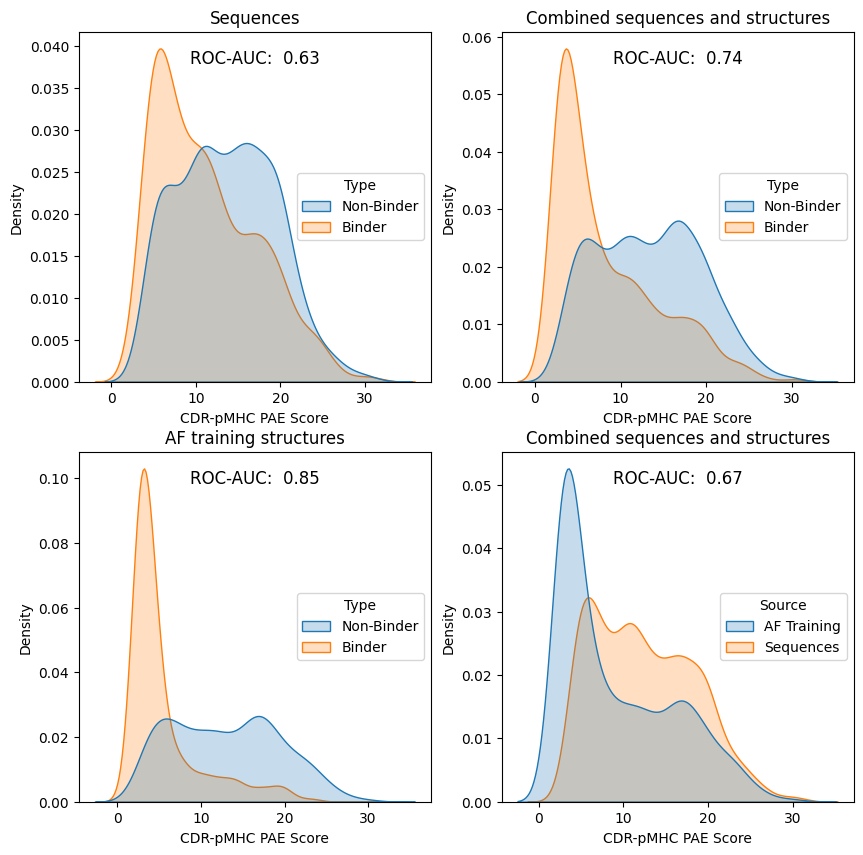

In [12]:
fig, axes = plot_separation(confidence_scores_down_sample, x='cdr_pmhc_pae_score')

for ax in axes.flatten():
    ax.set_xlabel('CDR-pMHC PAE Score')

plt.savefig('../report/figures/pae_aggregator_normalisation_original_kdes.svg')
plt.show()

Here, we see an effect that the distribution that the pairing comes from can have a larger effect than the label of that pairing.

In [13]:
confidence_scores_multiple_tcrs = confidence_scores.merge(
    sequences_1500, how='right', left_on='name', right_index=True
).query('multiple_tcrs')

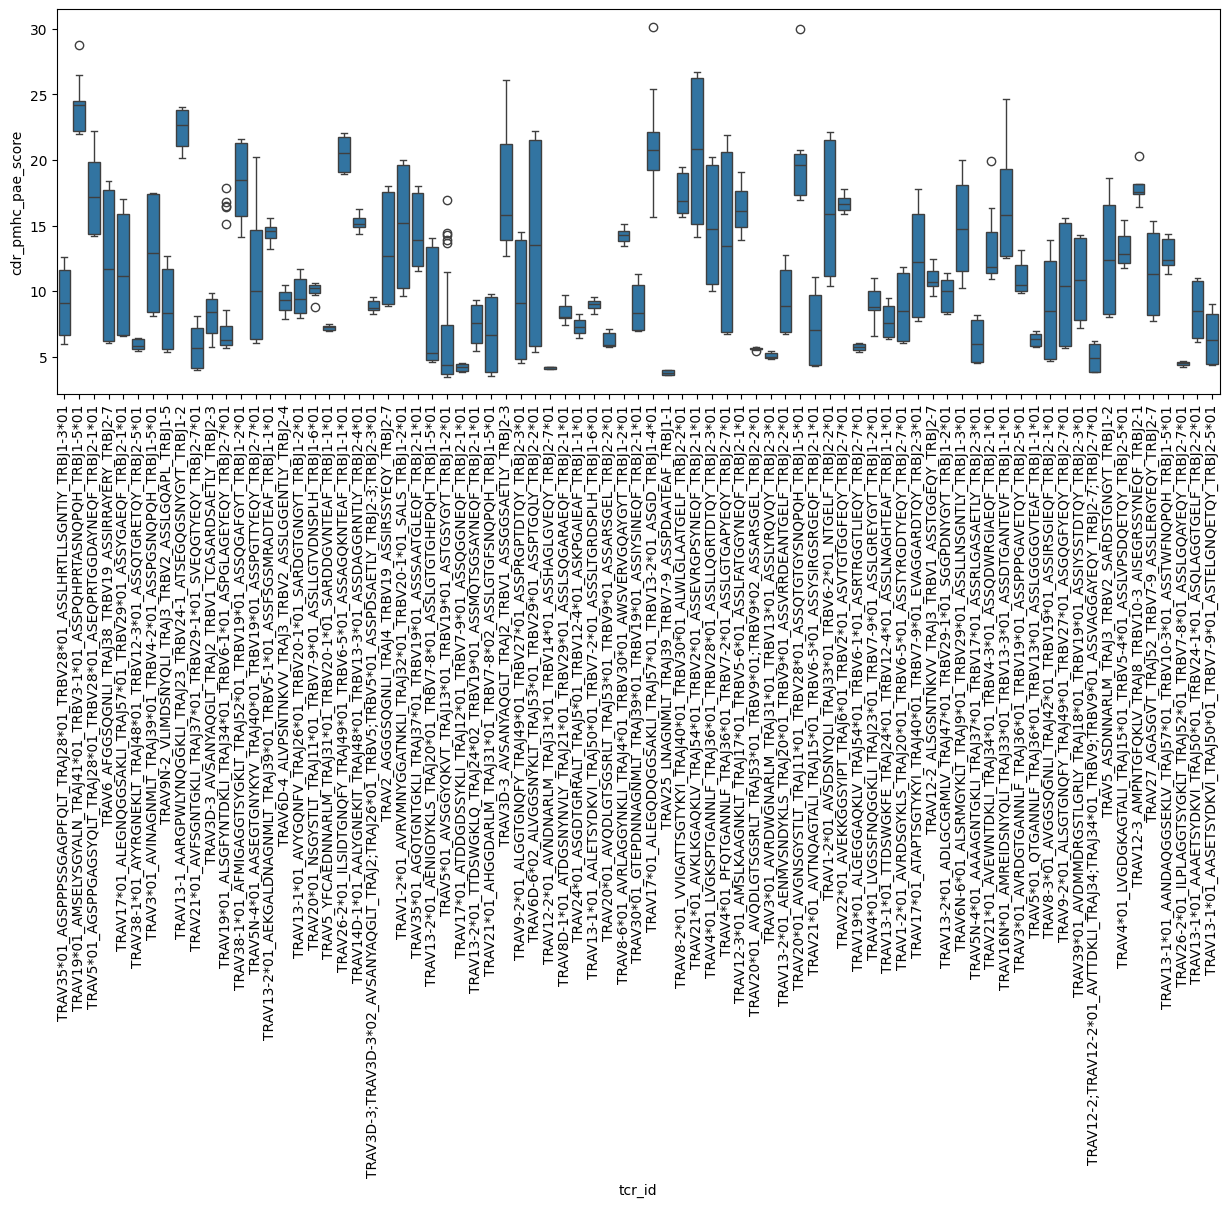

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))
sns.boxplot(confidence_scores_multiple_tcrs, x='tcr_id', y='cdr_pmhc_pae_score', ax=ax)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.show()

In [15]:
pg.kruskal(confidence_scores_multiple_tcrs, dv='cdr_pmhc_pae_score', between='tcr_id')

,Source,ddof1,H,p-unc
Kruskal,tcr_id,78,675.999254,4.370554e-96


In [16]:
confidence_scores_multiple_pmhcs = confidence_scores.merge(
    sequences_1500, how='right', left_on='name', right_index=True
).query('multiple_pmhcs')

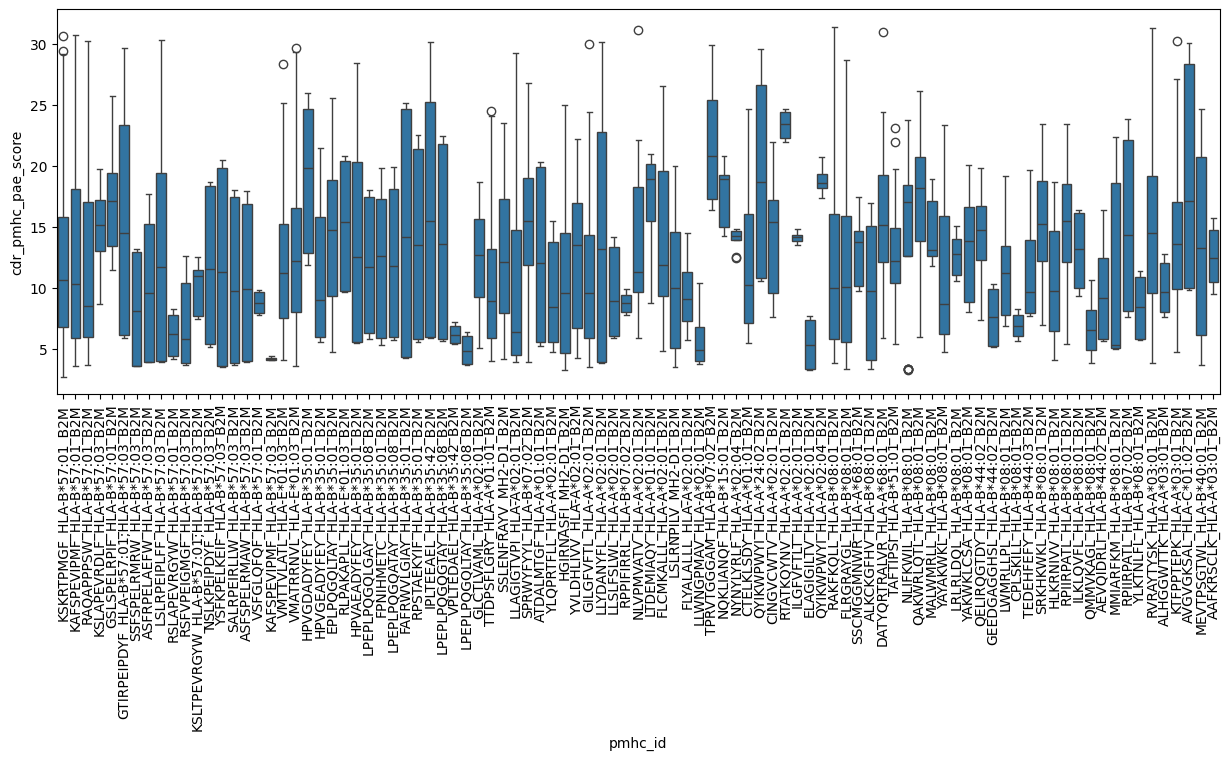

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))
sns.boxplot(
    confidence_scores_multiple_pmhcs,
    x='pmhc_id',
    y='cdr_pmhc_pae_score',
    ax=ax,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.show()

In [18]:
pg.kruskal(confidence_scores_multiple_pmhcs, dv='cdr_pmhc_pae_score', between='pmhc_id')

,Source,ddof1,H,p-unc
Kruskal,pmhc_id,94,844.939177,4.166156e-121


## Model

In [19]:
with h5py.File('../data/processed/af3_af3_tcrmodel2_pae.h5', 'r') as fh:
    paes = fh['pae'][:]

    names = np.array([name.decode() for name in fh['id'][:]])
    seeds = fh['seed'][:]
    samples = fh['sample'][:]

    folds = fh['fold'][:]

### Untrained

In [20]:
untrained_predictions = pd.read_csv('../data/processed/af3_af3_tcrmodel2_pae_aggregator_predictions_untrained.csv')
untrained_predictions = untrained_predictions.rename({'prediction': 'untrained_prediction'}, axis='columns')

In [21]:
model = PAEAggregator(3040)
model.eval()

latents = torch.mul(model.weights, torch.Tensor(paes)).cpu().detach().numpy()

untrained_predictions = untrained_predictions.merge(
    pd.DataFrame(
        {
            'name': names,
            'seed': seeds,
            'sample': samples,
            'untrained_latents': list(latents),
        }
    )
)

In [22]:
confidence_scores_down_sample = confidence_scores_down_sample.merge(
    untrained_predictions, how='left', on=['name', 'seed', 'sample']
)

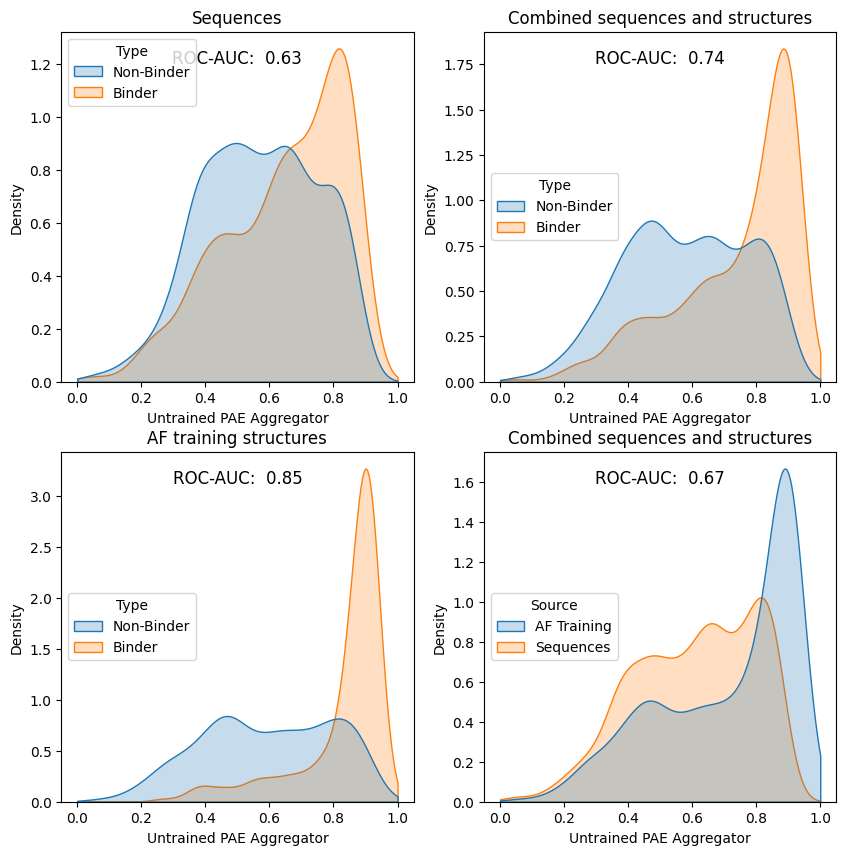

In [23]:
fig, axes = plot_separation(confidence_scores_down_sample, x='untrained_prediction', invert_roc_auc=True, clip=(0, 1))

for ax in axes.flatten():
    ax.set_xlabel('Untrained PAE Aggregator')

plt.savefig('../report/figures/pae_aggregator_normalisation_untrained_kdes.svg')
plt.show()

In [24]:
untrained_umap = umap.UMAP(random_state=123).fit_transform(
    np.vstack(confidence_scores_down_sample['untrained_latents'])
)

/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


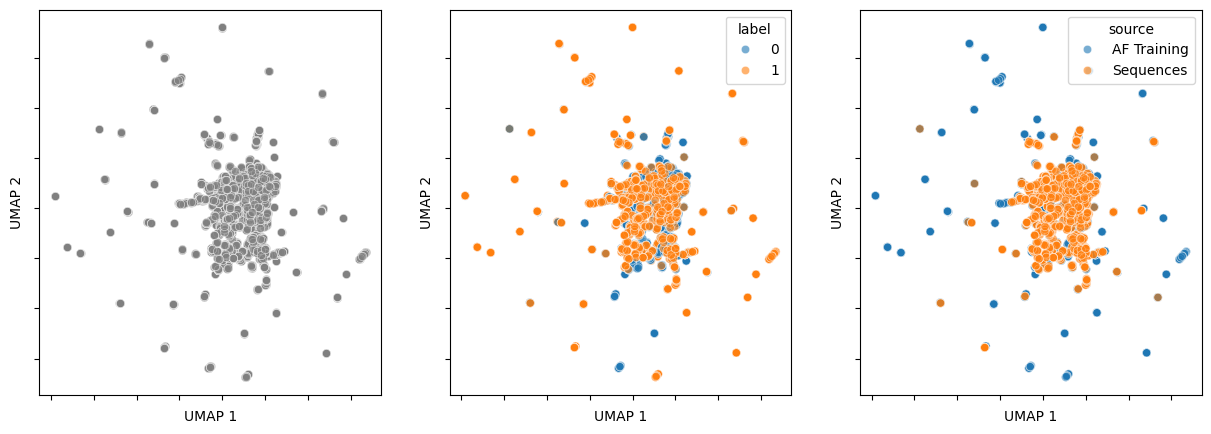

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.scatterplot(x=untrained_umap[:, 0], y=untrained_umap[:, 1], alpha=0.6, color='grey', ax=axes[0])
sns.scatterplot(
    x=untrained_umap[:, 0], y=untrained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['label'], ax=axes[1]
)
sns.scatterplot(
    x=untrained_umap[:, 0], y=untrained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['source'], ax=axes[2]
)

for ax in axes:
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

plt.show()

In [26]:
untrained_predictions_multiple_tcrs = untrained_predictions.merge(
    sequences_1500, how='right', left_on='name', right_index=True
).query('multiple_tcrs')

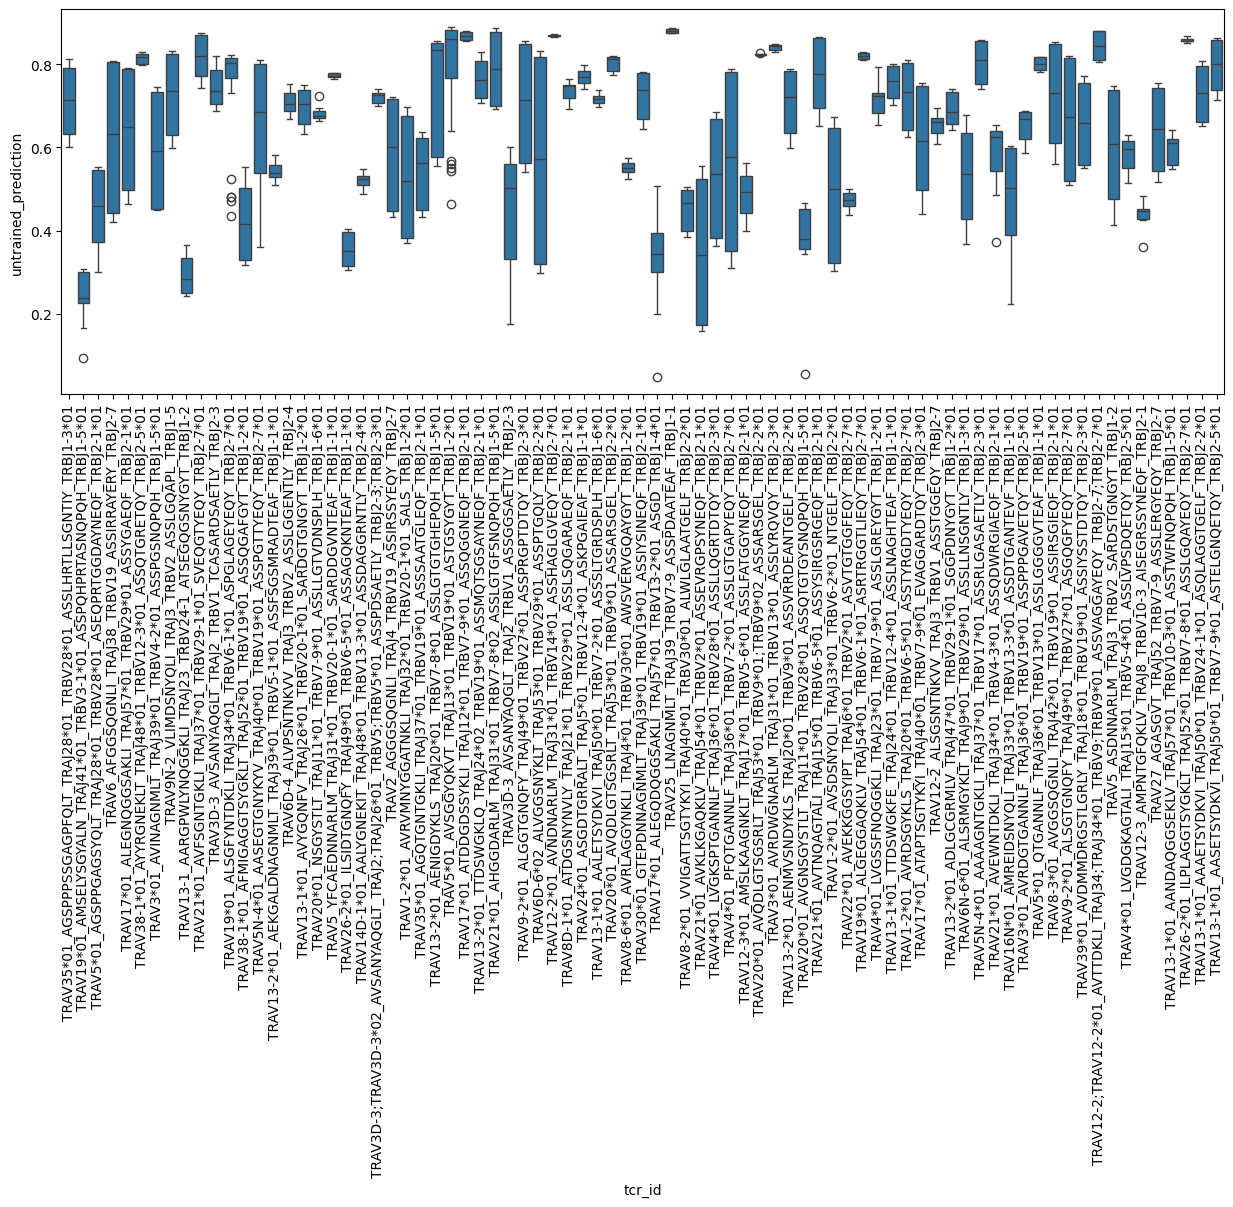

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))

sns.boxplot(untrained_predictions_multiple_tcrs, x='tcr_id', y='untrained_prediction', ax=ax)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.show()

In [28]:
pg.kruskal(untrained_predictions_multiple_tcrs, dv='untrained_prediction', between='tcr_id')

,Source,ddof1,H,p-unc
Kruskal,tcr_id,78,675.999309,4.370449e-96


In [29]:
untrained_predictions_multiple_pmhcs = untrained_predictions.merge(
    sequences_1500, how='right', left_on='name', right_index=True
).query('multiple_pmhcs')

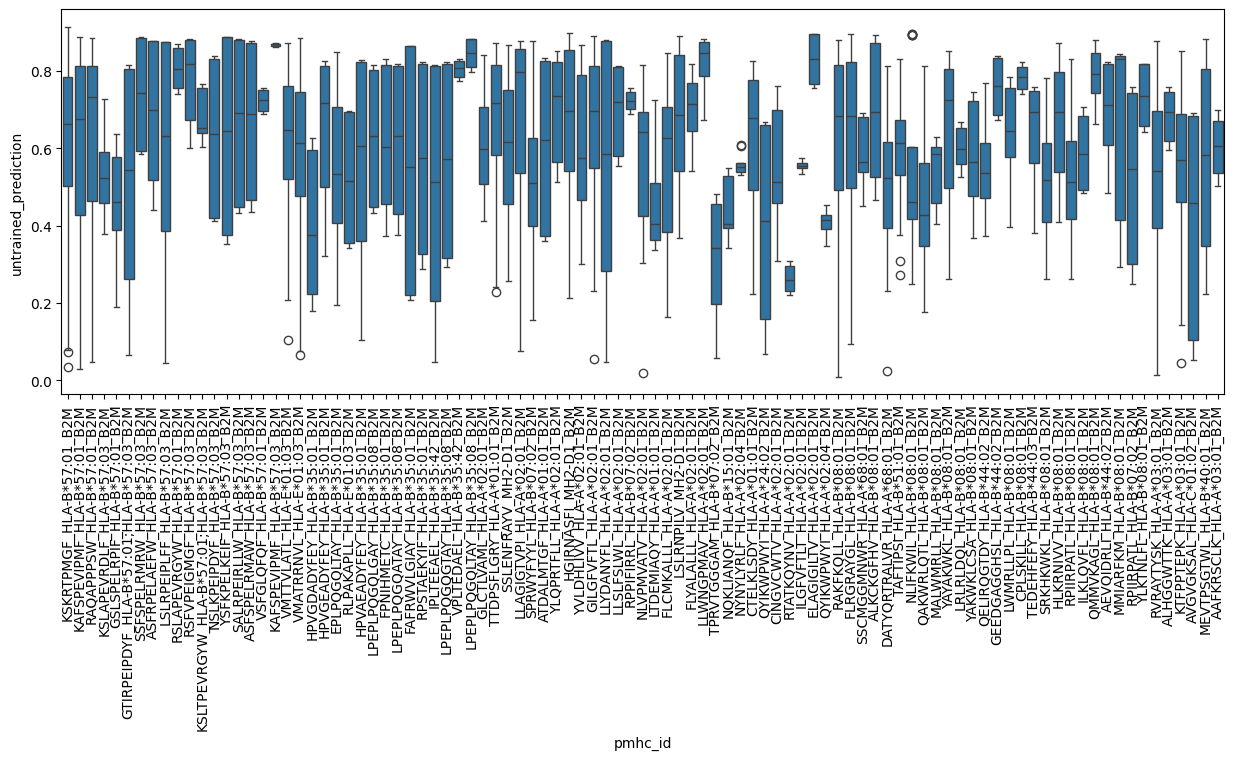

In [30]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))

sns.boxplot(untrained_predictions_multiple_pmhcs, x='pmhc_id', y='untrained_prediction', ax=ax)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.show()

In [31]:
pg.kruskal(untrained_predictions_multiple_pmhcs, dv='untrained_prediction', between='tcr_id')

,Source,ddof1,H,p-unc
Kruskal,tcr_id,1298,6619.760998,0.0


### Trained

In [32]:
trained_predictions = pd.read_csv('../data/processed/af3_af3_tcrmodel2_pae_aggregator_predictions_trained.csv')
trained_predictions = trained_predictions.rename({'prediction': 'trained_prediction'}, axis='columns')

In [33]:
trained_latents = pd.DataFrame()

for fold in sorted(np.unique(folds)):
    model = PAEAggregator(3040)
    model.load_state_dict(
        torch.load(
            f'../models/PAEAggregator_af3_af3_tcrmodel2/model_{fold}.pt',
            weights_only=True,
            map_location=torch.device('cpu'),
        ),
    )
    model.eval()

    fold_mask = folds == fold
    latents = torch.mul(model.weights, torch.Tensor(paes[fold_mask])).cpu().detach().numpy()

    trained_latents = pd.concat(
        [
            trained_latents,
            pd.DataFrame(
                {
                    'name': names[fold_mask],
                    'seed': seeds[fold_mask],
                    'sample': samples[fold_mask],
                    'trained_latents': list(latents),
                }
            ),
        ]
    )

trained_predictions = trained_predictions.merge(trained_latents)

In [34]:
confidence_scores_down_sample = confidence_scores_down_sample.merge(
    trained_predictions, how='left', on=['name', 'seed', 'sample']
)

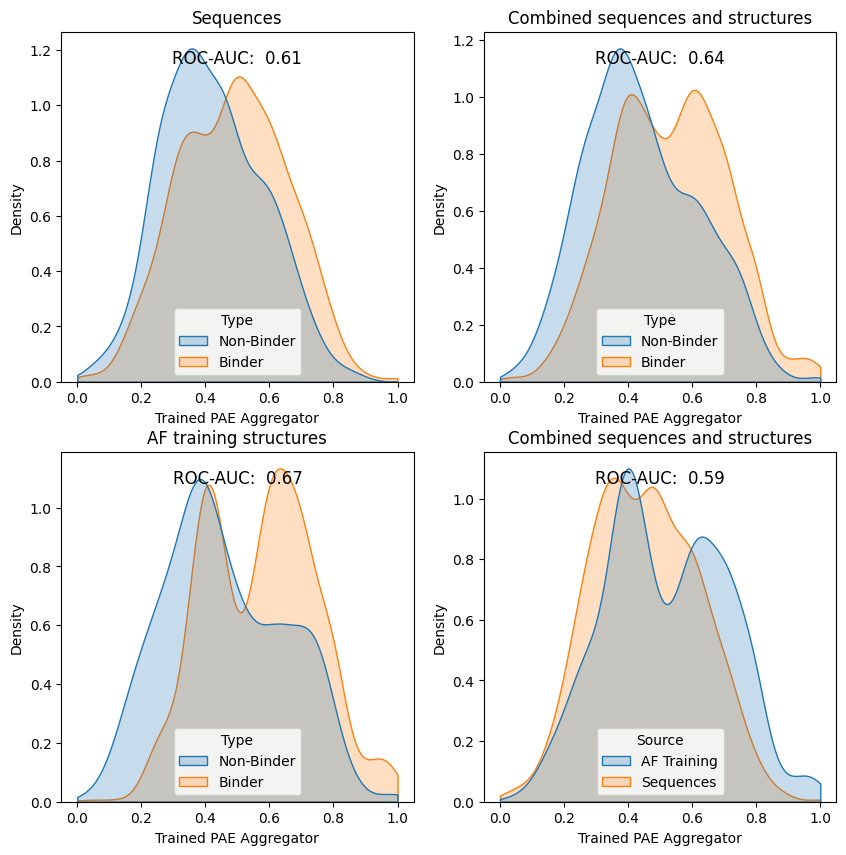

In [35]:
fig, axes = plot_separation(confidence_scores_down_sample, x='trained_prediction', invert_roc_auc=True, clip=(0, 1))

for ax in axes.flatten():
    ax.set_xlabel('Trained PAE Aggregator')

plt.savefig('../report/figures/pae_aggregator_normalisation_trained_kdes.svg')
plt.show()

In [36]:
trained_umap = umap.UMAP(random_state=123).fit_transform(np.vstack(confidence_scores_down_sample['trained_latents']))

/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


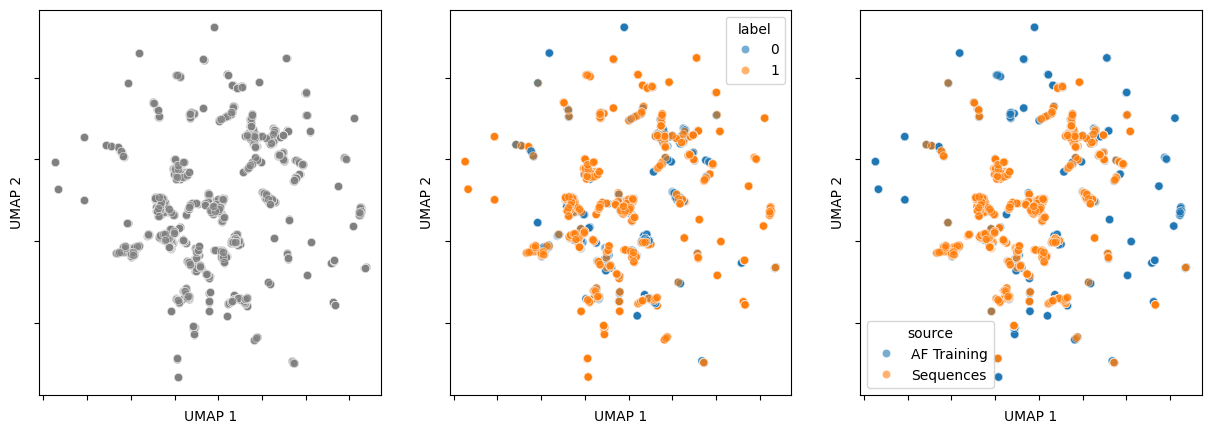

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.scatterplot(x=trained_umap[:, 0], y=trained_umap[:, 1], alpha=0.6, color='grey', ax=axes[0])
sns.scatterplot(
    x=trained_umap[:, 0], y=trained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['label'], ax=axes[1]
)
sns.scatterplot(
    x=trained_umap[:, 0], y=trained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['source'], ax=axes[2]
)

for ax in axes:
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

plt.show()

In [38]:
trained_predictions_multiple_tcrs = trained_predictions.merge(
    sequences_1500, how='right', left_on='name', right_index=True
).query('multiple_tcrs')

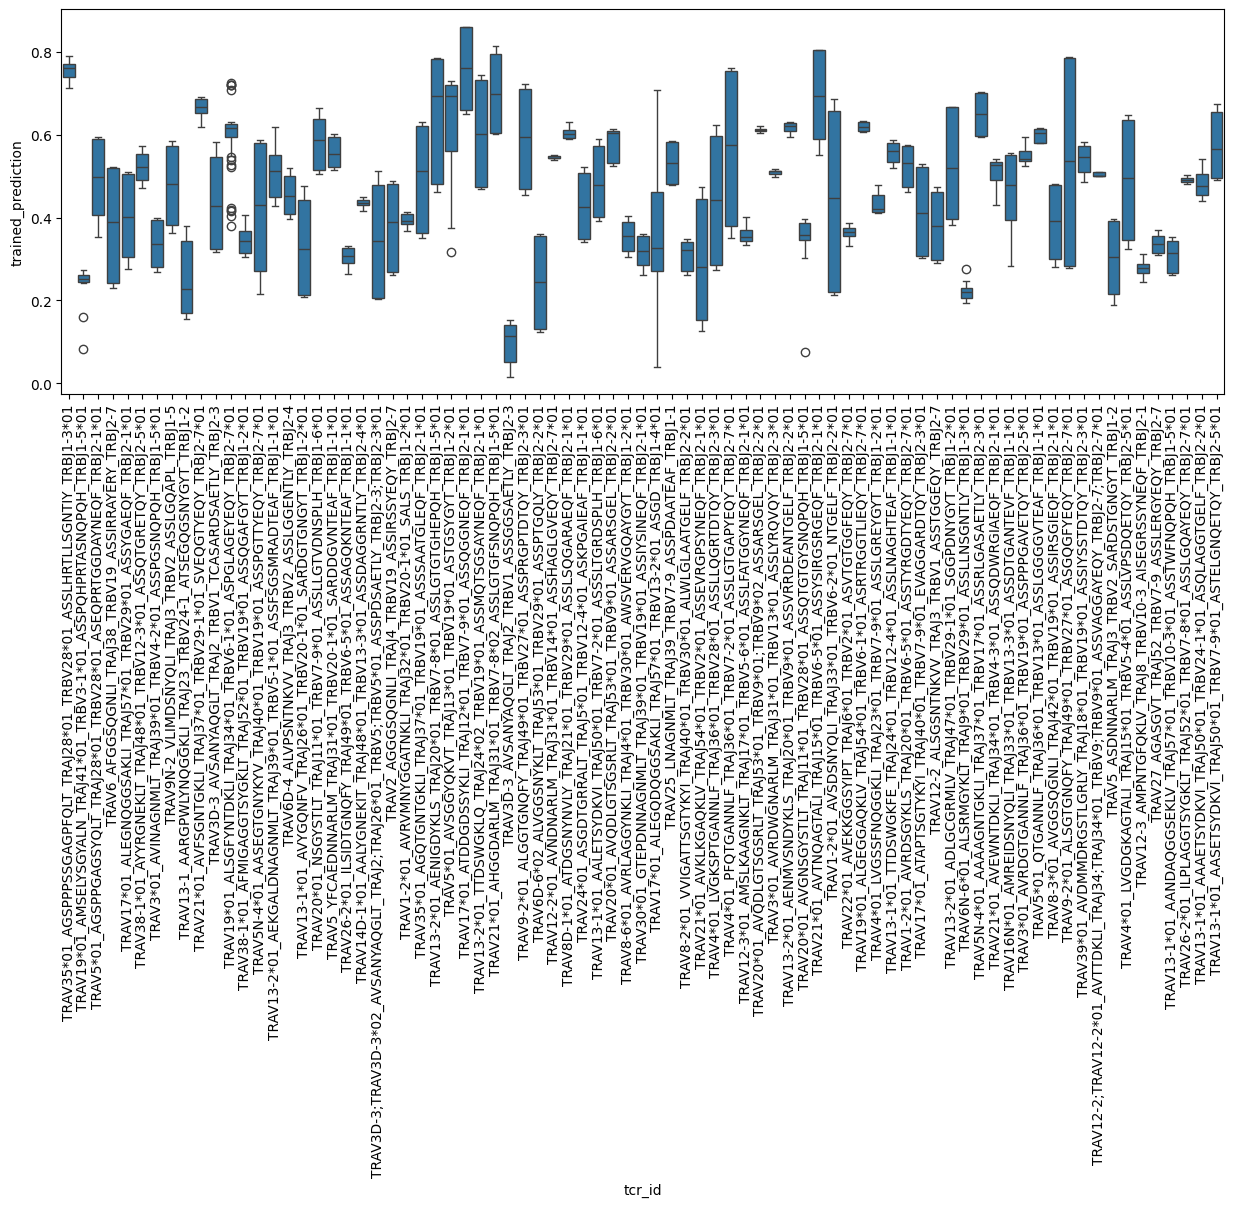

In [39]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))

sns.boxplot(
    trained_predictions_multiple_tcrs,
    x='tcr_id',
    y='trained_prediction',
    ax=ax,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.show()

In [40]:
pg.kruskal(trained_predictions_multiple_tcrs, dv='trained_prediction', between='tcr_id')

,Source,ddof1,H,p-unc
Kruskal,tcr_id,78,641.680945,1.720930e-89


In [41]:
trained_predictions_multiple_pmhcs = trained_predictions.merge(
    sequences_1500, how='right', left_on='name', right_index=True
).query('multiple_pmhcs')

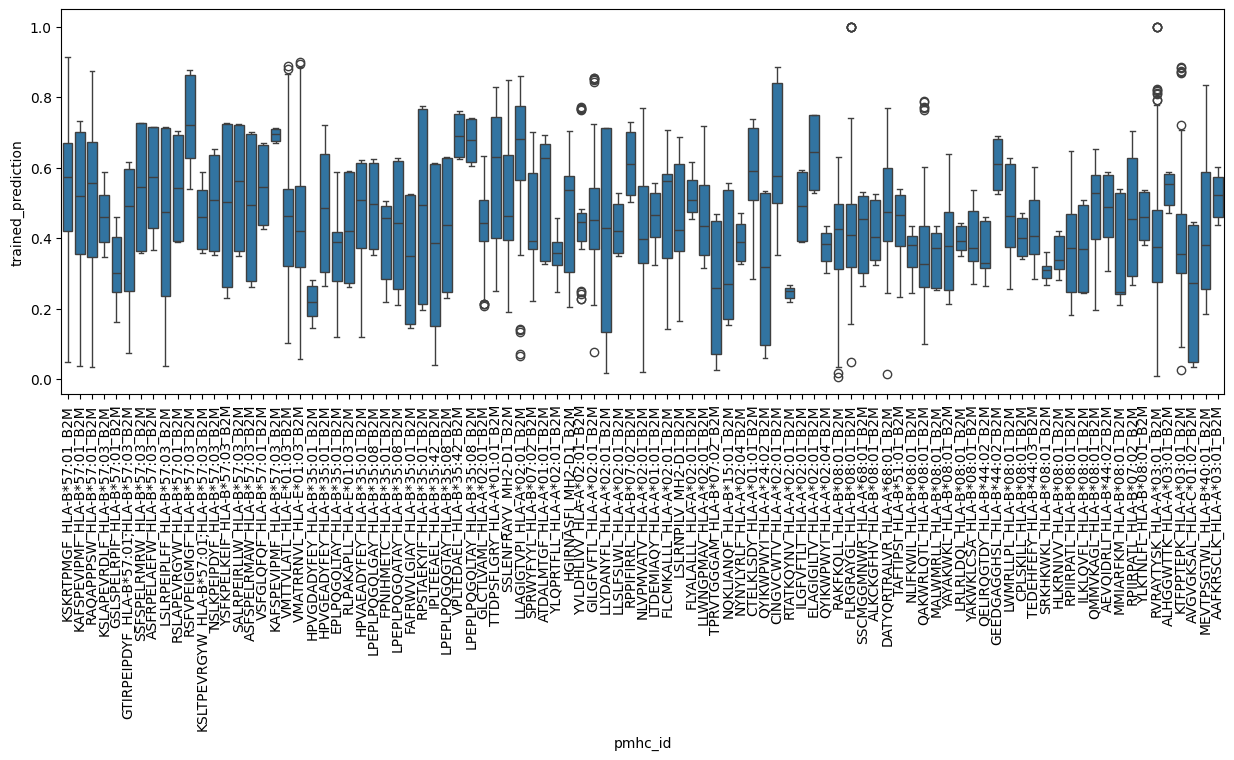

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))

sns.boxplot(
    trained_predictions_multiple_pmhcs,
    x='pmhc_id',
    y='trained_prediction',
    ax=ax,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.show()

In [43]:
pg.kruskal(trained_predictions_multiple_pmhcs, dv='trained_prediction', between='pmhc_id')

,Source,ddof1,H,p-unc
Kruskal,pmhc_id,94,1141.233574,1.870629e-179


## Combined Results

In [44]:
confidence_scores_down_sample_sequences = confidence_scores_down_sample[
    confidence_scores_down_sample['source'] == 'Sequences'
]

rng = np.random.default_rng(SEED)

roc_auc_scores = {
    'sample_num': [],
    'prediction_status': [],
    'antigen_specificity': [],
    'data_source': [],
}

for sample_num in range(1, NUM_SAMPLES + 1):
    sample = confidence_scores_down_sample.sample(SAMPLE_SIZE, random_state=rng)
    sample_sequences = confidence_scores_down_sample_sequences.sample(SAMPLE_SIZE, random_state=rng)

    for prediction_status in ('untrained_prediction', 'trained_prediction'):
        roc_auc_scores['sample_num'].append(sample_num)
        roc_auc_scores['prediction_status'].append(prediction_status)

        roc_auc_scores['antigen_specificity'].append(
            roc_auc_score(sample_sequences['label'], sample_sequences[prediction_status])
        )

        roc_auc_scores['data_source'].append(1 - roc_auc_score(sample['source'], sample[prediction_status]))

roc_auc_scores = pd.DataFrame(roc_auc_scores)

In [45]:
roc_auc_scores_agg = roc_auc_scores.groupby('prediction_status').agg(
    {'antigen_specificity': ['mean', 'sem'], 'data_source': ['mean', 'sem']}
)

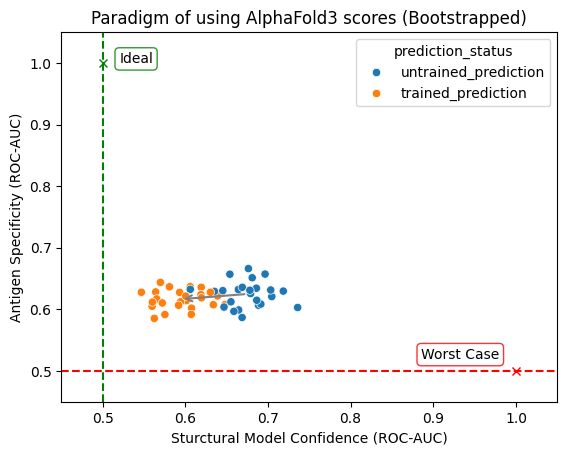

In [46]:
ax = sns.scatterplot(roc_auc_scores, x='data_source', y='antigen_specificity', hue='prediction_status')

ax.annotate(
    '',
    xy=roc_auc_scores_agg[roc_auc_scores_agg.index == 'trained_prediction']
    .iloc[0][[('data_source', 'mean'), ('antigen_specificity', 'mean')]]
    .tolist(),
    xytext=roc_auc_scores_agg[roc_auc_scores_agg.index == 'untrained_prediction']
    .iloc[0][[('data_source', 'mean'), ('antigen_specificity', 'mean')]]
    .tolist(),
    arrowprops={'arrowstyle': '->', 'color': 'gray', 'lw': 1.5},
    fontsize=11,
    ha='center',
)

ax.plot([0.5], [1.0], marker='x', color='green')
ax.text(
    0.52, 1.0, 'Ideal', bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'edgecolor': 'green', 'alpha': 0.8}
)
ax.axvline(0.5, color='green', linestyle='--')

ax.plot([1.0], [0.5], marker='x', color='red')
ax.text(
    0.98,
    0.52,
    'Worst Case',
    ha='right',
    bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'edgecolor': 'red', 'alpha': 0.8},
)
ax.axhline(0.5, color='red', linestyle='--')

ax.set_xlim(0.45, 1.05)
ax.set_ylim(0.45, 1.05)

ax.set_ylabel('Antigen Specificity (ROC-AUC)')
ax.set_xlabel('Sturctural Model Confidence (ROC-AUC)')
ax.set_title('Paradigm of using AlphaFold3 scores (Bootstrapped)')

plt.savefig('../report/figures/pae_aggregator_normalisation_roc_aucs_bootstrapped.svg')
plt.show()

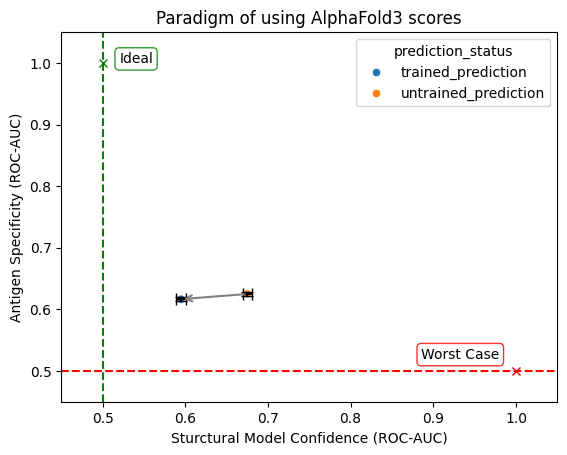

In [47]:
ax = sns.scatterplot(
    roc_auc_scores_agg, x=('data_source', 'mean'), y=('antigen_specificity', 'mean'), hue='prediction_status'
)
ax.errorbar(
    roc_auc_scores_agg[('data_source', 'mean')],
    roc_auc_scores_agg[('antigen_specificity', 'mean')],
    xerr=roc_auc_scores_agg[('data_source', 'sem')],
    yerr=roc_auc_scores_agg[('antigen_specificity', 'sem')],
    capsize=4,
    fmt='none',
    ecolor='black',
)

ax.annotate(
    '',
    xy=roc_auc_scores_agg[roc_auc_scores_agg.index == 'trained_prediction']
    .iloc[0][[('data_source', 'mean'), ('antigen_specificity', 'mean')]]
    .tolist(),
    xytext=roc_auc_scores_agg[roc_auc_scores_agg.index == 'untrained_prediction']
    .iloc[0][[('data_source', 'mean'), ('antigen_specificity', 'mean')]]
    .tolist(),
    arrowprops={'arrowstyle': '->', 'color': 'gray', 'lw': 1.5},
    fontsize=11,
    ha='center',
)

ax.plot([0.5], [1.0], marker='x', color='green')
ax.text(
    0.52, 1.0, 'Ideal', bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'edgecolor': 'green', 'alpha': 0.8}
)
ax.axvline(0.5, color='green', linestyle='--')

ax.plot([1.0], [0.5], marker='x', color='red')
ax.text(
    0.98,
    0.52,
    'Worst Case',
    ha='right',
    bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'edgecolor': 'red', 'alpha': 0.8},
)
ax.axhline(0.5, color='red', linestyle='--')

ax.set_xlim(0.45, 1.05)
ax.set_ylim(0.45, 1.05)

ax.set_ylabel('Antigen Specificity (ROC-AUC)')
ax.set_xlabel('Sturctural Model Confidence (ROC-AUC)')
ax.set_title('Paradigm of using AlphaFold3 scores')

plt.savefig('../report/figures/pae_aggregator_normalisation_roc_aucs_bootstrapped_agg.svg')
plt.show()

In [48]:
dvs = ['antigen_specificity', 'data_source']
X = roc_auc_scores[roc_auc_scores['prediction_status'] == 'untrained_prediction'][dvs]
Y = roc_auc_scores[roc_auc_scores['prediction_status'] == 'trained_prediction'][dvs]

ipy_display.display(pg.multivariate_ttest(X, Y))


print('Post-hoc testing:\n')
significance_level = 0.05 / len(dvs)

print('Aspect                 Statistic  P-Value     Significant?')
print('----------------------------------------------------------')
for dv in dvs:
    stat, p_val = stats.ttest_ind(X[dv], Y[dv])
    print(f"{dv.replace('_', ' ').title(): <22} {stat: <10.2f} {p_val: <12.2e}{p_val < significance_level}")

,T2,F,df1,df2,pval
hotelling,106.513831,52.147397,2,47,1.170674e-12


Post-hoc testing:

Aspect                 Statistic  P-Value     Significant?
----------------------------------------------------------
Antigen Specificity    1.68       1.00e-01    False
Data Source            10.19      1.36e-13    True


## Compairing variance per TCR or pMHC between trained and untrained

In [49]:
prediction_means_multiple_tcrs = (
    pd.concat(
        [
            untrained_predictions_multiple_tcrs.groupby('tcr_id')['untrained_prediction'].mean().to_frame(),
            trained_predictions_multiple_tcrs.groupby('tcr_id')['trained_prediction'].mean().to_frame(),
        ],
        axis=1,
    )
    .reset_index()
    .melt(
        id_vars='tcr_id',
        value_vars=['untrained_prediction', 'trained_prediction'],
        var_name='status',
        value_name='prediction_mean',
    )
)

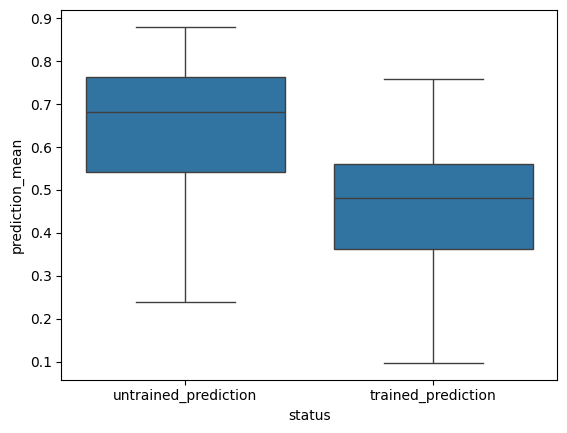

In [50]:
sns.boxplot(prediction_means_multiple_tcrs, x='status', y='prediction_mean')
plt.show()

In [51]:
pg.homoscedasticity(prediction_means_multiple_tcrs, dv='prediction_mean', group='status')

,W,pval,equal_var
levene,0.987813,0.321817,True


In [52]:
prediction_means_multiple_pmhcs = (
    pd.concat(
        [
            untrained_predictions_multiple_pmhcs.groupby('pmhc_id')['untrained_prediction'].mean().to_frame(),
            trained_predictions_multiple_pmhcs.groupby('pmhc_id')['trained_prediction'].mean().to_frame(),
        ],
        axis=1,
    )
    .reset_index()
    .melt(
        id_vars='pmhc_id',
        value_vars=['untrained_prediction', 'trained_prediction'],
        var_name='status',
        value_name='prediction_mean',
    )
)

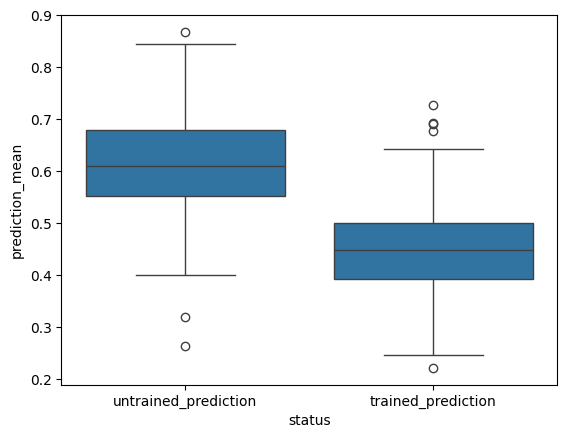

In [53]:
sns.boxplot(prediction_means_multiple_pmhcs, x='status', y='prediction_mean')
plt.show()

In [54]:
pg.homoscedasticity(prediction_means_multiple_pmhcs, dv='prediction_mean', group='status')

,W,pval,equal_var
levene,0.690588,0.407019,True
